개발 기간: 2025.04 ~ 2025.07
- 딸기 병해 분류 모델 개발 당시의 Colab 실험 기록입니다. 여러 학습·변환 실험이 포함되어 있으며, 전체 셀을 순서대로 실행하는 용도로 정리된 노트북은 아닙니다.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/strawberry_disease_dataset.zip'  # 업로드한 zip 경로
extract_path = '/content/strawberry_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [ ]:
import os

base_dir = '/content/strawberry_dataset'

for root, dirs, files in os.walk(base_dir):
    level = root.replace(base_dir, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    for f in files[:3]:  # 파일이 너무 많을 수 있어서 처음 3개만 출력
        print(f"{indent}    {f}")


strawberry_dataset/
    Dataset.txt
    test/
        leaf_spot569.json
        angular_leafspot372.json
        powdery_mildew_leaf491.json
    train/
        powdery_mildew_leaf168.jpg
        powdery_mildew_leaf514.json
        angular_leafspot247.json
    val/
        leaf_spot195.json
        angular_leafspot241.json
        anthracnose_fruit_rot29.json
    Test Disease Severity Level/
        Level 1/
            leaf_spot569.json
            angular_leafspot372.json
            powdery_mildew_leaf491.json
        Level 2/
            gray_mold487.json
            powdery_mildew_leaf488.json
            leaf_spot621.json


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 이미지 전처리 및 train/validation 분할
datagen = ImageDataGenerator(
    rescale=1./255,            # 픽셀값을 0~1로 정규화
    validation_split=0.2       # 전체의 20%를 검증 데이터로 사용
)

# 학습용 데이터
train_generator = datagen.flow_from_directory(
    base_dir,
    target_size=(224, 224),    # 이미지 크기 통일
    batch_size=32,
    class_mode='categorical',  # 다중 클래스 분류
    subset='training'
)

# 검증용 데이터
val_generator = datagen.flow_from_directory(
    base_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)


Found 2596 images belonging to 4 classes.
Found 647 images belonging to 4 classes.


In [ ]:
import os
import shutil

src_root = '/content/strawberry_dataset'  # 원본 데이터셋 경로 (train, val, test 포함)
dst_root = '/content/organized_dataset'   # 분류 후 저장할 경로

# 이미지 확장자 허용 리스트
img_exts = ('.jpg', '.jpeg', '.png')

# 파일명에서 병명 추출 함수
def extract_disease_name(fname):
    return fname.rsplit('.', 1)[0].rsplit('_', 1)[0]

# 병명에 따라 분류할 폴더 결정하는 함수
def classify_folder(disease_name):
    disease_name = disease_name.lower()
    if 'angular' in disease_name:
        return 'angular'
    elif 'powdery_mildew' in disease_name:
        return 'powdery_mildew'
    elif 'leaf' in disease_name:
        return 'leaf'
    elif 'gray' in disease_name or 'grey' in disease_name:
        return 'gray'
    elif 'anthracnose_fruit' in disease_name:
        return 'anthracnose_fruit'
    elif 'blossom' in disease_name:
        return 'blossom'
    else:
        return None  # 필요없으면 None 처리해서 무시

# train, val, test 폴더 전부 처리
for phase in ['train', 'val', 'test']:
    src_phase_dir = os.path.join(src_root, phase)
    if not os.path.exists(src_phase_dir):
        print(f"❌ {phase} 폴더가 없습니다: {src_phase_dir}")
        continue

    for fname in os.listdir(src_phase_dir):
        if fname.lower().endswith(img_exts):
            disease_name = extract_disease_name(fname)
            target_folder = classify_folder(disease_name)
            if target_folder is None:
                continue  # 분류하지 않는 이미지

            dst_dir = os.path.join(dst_root, phase, target_folder)
            os.makedirs(dst_dir, exist_ok=True)

            src_path = os.path.join(src_phase_dir, fname)
            dst_path = os.path.join(dst_dir, fname)
            shutil.copy2(src_path, dst_path)

print("✅ 분류 완료!")


✅ 분류 완료!


In [ ]:
import os

def check_dataset_structure(base_dir):
    for split in ['train', 'val', 'test']:
        split_path = os.path.join(base_dir, split)
        print(f"\n[{split.upper()} SET]")
        if not os.path.exists(split_path):
            print("❌ 폴더가 없습니다.")
            continue

        for disease in os.listdir(split_path):
            disease_path = os.path.join(split_path, disease)
            if os.path.isdir(disease_path):
                image_count = len([
                    fname for fname in os.listdir(disease_path)
                    if fname.endswith('.jpg')
                ])
                print(f"📁 {disease} → {image_count}장")

check_dataset_structure('/content/strawberry_dataset')




[TRAIN SET]
📁 angular → 245장
📁 powdery_mildew → 399장
📁 leaf → 382장
📁 gray → 255장
📁 anthracnose_fruit → 52장
📁 blossom → 117장

[VAL SET]
📁 angular → 43장
📁 powdery_mildew → 75장
📁 leaf → 71장
📁 gray → 77장
📁 anthracnose_fruit → 12장
📁 blossom → 29장

[TEST SET]
📁 angular → 147장
📁 powdery_mildew → 194장
📁 leaf → 162장
📁 gray → 145장
📁 anthracnose_fruit → 33장
📁 blossom → 62장


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 경로
base_dir = '/content/strawberry_dataset'

# 이미지 전처리 설정
img_size = (224, 224)
batch_size = 32

# 학습용 데이터 증강
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

# 검증/테스트용은 증강 없이 정규화만
val_test_datagen = ImageDataGenerator(rescale=1./255)

# 폴더에서 이미지 불러오기
train_generator = train_datagen.flow_from_directory(
    directory=os.path.join(base_dir, 'train'),
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

val_generator = val_test_datagen.flow_from_directory(
    directory=os.path.join(base_dir, 'val'),
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

test_generator = val_test_datagen.flow_from_directory(
    directory=os.path.join(base_dir, 'test'),
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False  # 평가 시 순서 고정
)


Found 1450 images belonging to 6 classes.
Found 307 images belonging to 6 classes.
Found 743 images belonging to 6 classes.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 201s 4s/step - accuracy: 0.3549 - loss: 1.7142 - val_accuracy: 0.6091 - val_loss: 0.9485
Epoch 2/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 195s 4s/step - accuracy: 0.6547 - loss: 0.9163 - val_accuracy: 0.8404 - val_loss: 0.5449
Epoch 3/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 192s 4s/step - accuracy: 0.7568 - loss: 0.7162 - val_accuracy: 0.7752 - val_loss: 0.5987
Epoch 4/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 208s 4s/step - accuracy: 0.7816 - loss: 0.6101 - val_accuracy: 0.8436 - val_loss: 0.5004
Epoch 5/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 195s 4s/step - accuracy: 0.8319 - loss: 0.4892 - val_accuracy: 0.7785 - val_loss: 0.5490
Epoch 6/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 192s 4s/step - accuracy: 0.8128 - loss: 0.4979 - val_accuracy: 0.8795 - val_loss: 0.3635
Epoch 7/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 198s 4s/step - accuracy: 0.8404 - loss: 0.4431 - val_accuracy: 0.8860 - val_loss: 0.3364
Epoch 8/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 193s 4s/step - accuracy: 0.8383 - loss: 0.4247 - val_accuracy: 0.8893 - v

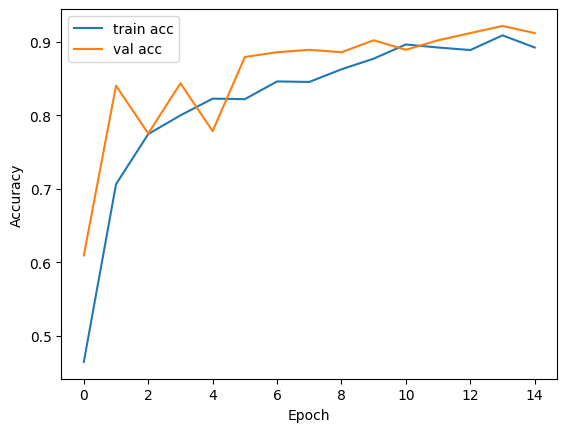

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

num_classes = 6  # 클래스 개수

# CNN 모델 설계
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

# 모델 요약
model.summary()

# 컴파일
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 학습
history = model.fit(
    train_generator,
    epochs=15,
    validation_data=val_generator
)

# 학습 결과 시각화
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/strawberry_disease2.zip'  # 업로드한 zip 경로
extract_path = '/content/strawberry_dataset2'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [ ]:
import os
import shutil
import random

src_root = '/content/strawberry_dataset2/union_dataset'
dst_root = '/content/cleaned_strawberry_dataset'

# 사용할 클래스 목록 (한국어 주석 포함)
selected_classes = [
    'Strawberry___Leaf_scorch',        # 딸기 잎마름병
    'Strawberry___healthy',            # 건강한 딸기
    'powdery_mildew_fruit',            # 흰가루병 (과일)
    'powdery_mildew_leaf',             # 흰가루병 (잎)
    'anthracnose',                     # 탄저병
    'anthracnose_fruit_rot',           # 탄저병 과일썩음병
    'leaf_spot',                       # 잎반점병
    'angular_leafspot',                # 앵귤러 리프스팟 (Angular leaf spot)
    'blossom_blight',                  # 꽃마름병
    'verticillium_wilt'                # 버티실리움 시들음병
]

# gray_mold + grey_mold → gray_mold로 병합
gray_mold_combined_name = 'gray_mold'   # 회색곰팡이병
gray_mold_sources = ['gray_mold', 'grey_mold']

selected_classes.append(gray_mold_combined_name)

train_ratio = 0.8

for cls in selected_classes:
    if cls == gray_mold_combined_name:
        images = []
        for mold_cls in gray_mold_sources:
            src_dir = os.path.join(src_root, mold_cls)
            if os.path.exists(src_dir):
                images += [os.path.join(src_dir, f) for f in os.listdir(src_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if not images:
            print(f"❌ 회색곰팡이 관련 이미지 없음 (gray_mold/grey_mold)")
            continue
    else:
        src_dir = os.path.join(src_root, cls)
        if not os.path.exists(src_dir):
            print(f"❌ {cls} 폴더 없음")
            continue
        images = [os.path.join(src_dir, f) for f in os.listdir(src_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    random.shuffle(images)
    train_len = int(len(images) * train_ratio)
    train_imgs = images[:train_len]
    val_imgs = images[train_len:]

    for phase, img_list in zip(['train', 'val'], [train_imgs, val_imgs]):
        dst_dir = os.path.join(dst_root, phase, cls)
        os.makedirs(dst_dir, exist_ok=True)

        for src_path in img_list:
            img_name = os.path.basename(src_path)
            dst_path = os.path.join(dst_dir, img_name)
            shutil.copy2(src_path, dst_path)

print("✅ 선택 클래스 정리 및 회색곰팡이 병합 완료!")


✅ 선택 클래스 정리 및 회색곰팡이 병합 완료!


In [ ]:
import os

dataset_dir = '/content/cleaned_strawberry_dataset'

phases = ['train', 'val']

print("📊 클래스별 이미지 개수:")
print("=" * 40)

for phase in phases:
    phase_dir = os.path.join(dataset_dir, phase)
    print(f"\n📁 [{phase.upper()}] 데이터셋")
    print("-" * 30)
    if not os.path.exists(phase_dir):
        print(f"{phase_dir} 경로가 존재하지 않습니다.")
        continue

    total = 0
    for cls in sorted(os.listdir(phase_dir)):
        cls_path = os.path.join(phase_dir, cls)
        if os.path.isdir(cls_path):
            img_count = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
            total += img_count
            print(f"  📌 {cls:<25}: {img_count}장")
    print(f"  ✅ 총 이미지 수: {total}장")


📊 클래스별 이미지 개수:

📁 [TRAIN] 데이터셋
------------------------------
  📌 Strawberry___Leaf_scorch : 887장
  📌 Strawberry___healthy     : 364장
  📌 angular_leafspot         : 313장
  📌 anthracnose              : 27장
  📌 anthracnose_fruit_rot    : 68장
  📌 blossom_blight           : 143장
  📌 gray_mold                : 381장
  📌 leaf_spot                : 476장
  📌 powdery_mildew_fruit     : 98장
  📌 powdery_mildew_leaf      : 376장
  📌 verticillium_wilt        : 24장
  ✅ 총 이미지 수: 3157장

📁 [VAL] 데이터셋
------------------------------
  📌 Strawberry___Leaf_scorch : 222장
  📌 Strawberry___healthy     : 92장
  📌 angular_leafspot         : 79장
  📌 anthracnose              : 7장
  📌 anthracnose_fruit_rot    : 17장
  📌 blossom_blight           : 36장
  📌 gray_mold                : 96장
  📌 leaf_spot                : 120장
  📌 powdery_mildew_fruit     : 25장
  📌 powdery_mildew_leaf      : 94장
  📌 verticillium_wilt        : 7장
  ✅ 총 이미지 수: 795장


In [ ]:
import os
import shutil

dataset_root = '/content/strawberry_dataset'
cleaned_root = '/content/cleaned_strawberry_dataset2'

img_exts = ('.jpg', '.jpeg', '.png')

target_diseases = [
    'angular', 'powdery_mildew', 'leaf',
    'gray', 'grey', 'anthracnose_fruit', 'blossom'
]

def extract_disease_name(fname):
    return fname.rsplit('.', 1)[0].rsplit('_', 1)[0].lower()

def match_target_disease(disease_name):
    for target in target_diseases:
        if target in disease_name:
            # 'gray' 와 'grey'를 모두 'gray'로 통일
            return 'gray' if target in ['gray', 'grey'] else target
    return None

def gather_images_in_dir(dir_path):
    images = []
    for root, dirs, files in os.walk(dir_path):
        for f in files:
            if f.lower().endswith(img_exts):
                images.append(os.path.join(root, f))
    return images

# train, val, test 각각 처리
for subset in ['train', 'val', 'test']:
    src_dir = os.path.join(dataset_root, subset)
    if not os.path.exists(src_dir):
        print(f"경고: {src_dir} 폴더가 없습니다. 넘어갑니다.")
        continue

    images = gather_images_in_dir(src_dir)
    print(f"{subset}에서 {len(images)}장 이미지 발견")

    for img_path in images:
        fname = os.path.basename(img_path)
        disease_name = extract_disease_name(fname)
        matched = match_target_disease(disease_name)
        if matched is None:
            continue

        dst_dir = os.path.join(cleaned_root, subset, matched)
        os.makedirs(dst_dir, exist_ok=True)

        dst_path = os.path.join(dst_dir, fname)

        # 중복 방지
        if os.path.exists(dst_path):
            base, ext = os.path.splitext(fname)
            count = 1
            while os.path.exists(dst_path):
                dst_path = os.path.join(dst_dir, f"{base}_{count}{ext}")
                count += 1

        shutil.copy2(img_path, dst_path)

print(f"✅ '{cleaned_root}' 폴더에 train/val/test 구조 유지하며 병명별로 정리 완료!")


train에서 1450장 이미지 발견
val에서 307장 이미지 발견
test에서 743장 이미지 발견
✅ '/content/cleaned_strawberry_dataset2' 폴더에 train/val/test 구조 유지하며 병명별로 정리 완료!


In [ ]:
import shutil
import os

folder_path = '/content/Strawberry_DataSet'

if os.path.exists(folder_path):
    shutil.rmtree(folder_path)
    print(f"'{folder_path}' 폴더를 삭제했습니다.")
else:
    print(f"'{folder_path}' 폴더가 존재하지 않습니다.")


'/content/Strawberry_DataSet' 폴더를 삭제했습니다.


In [ ]:
import os
import shutil

dataset1 = '/content/cleaned_strawberry_dataset'
dataset2 = '/content/cleaned_strawberry_dataset2'
target_dir = '/content/Strawberry_DataSet'

# 1번 데이터셋 병명 → 최종 병명 매핑
dataset1_to_target = {
    'angular_leafspot': 'angular',
    'powdery_mildew_fruit': 'powdery_mildew',
    'powdery_mildew_leaf': 'powdery_mildew',
    'leaf_spot': 'leaf_spot',
    'gray_mold': 'gray_mold',
    'anthracnose_fruit_rot': 'anthracnose_fruit_rot',
    'anthracnose': 'anthracnose_fruit_rot',
    'blossom_blight': 'blossom_blight',
    'Strawberry___Leaf_scorch': 'Strawberry___Leaf_scorch',
    'Strawberry___healthy': 'Strawberry___healthy',
    'verticillium_wilt': 'verticillium_wilt',
}

# 2번 데이터셋 병명 → 최종 병명 매핑
dataset2_to_target = {
    'angular': 'angular',
    'powdery_mildew': 'powdery_mildew',
    'leaf': 'leaf_spot',
    'gray': 'gray_mold',
    'anthracnose_fruit': 'anthracnose_fruit_rot',
    'blossom': 'blossom_blight',
}

subsets = ['train', 'val', 'test']

def copy_images(src_root, mapping):
    for subset in subsets:
        for src_class, target_class in mapping.items():
            src_path = os.path.join(src_root, subset, src_class)
            target_path = os.path.join(target_dir, subset, target_class)
            if not os.path.exists(src_path):
                print(f'폴더 없음: {src_path}')
                continue
            os.makedirs(target_path, exist_ok=True)

            for fname in os.listdir(src_path):
                src_file = os.path.join(src_path, fname)
                dst_file = os.path.join(target_path, fname)

                # 중복 파일명 방지
                base, ext = os.path.splitext(fname)
                count = 1
                while os.path.exists(dst_file):
                    dst_file = os.path.join(target_path, f"{base}_{count}{ext}")
                    count += 1

                shutil.copy2(src_file, dst_file)

os.makedirs(target_dir, exist_ok=True)

copy_images(dataset1, dataset1_to_target)
copy_images(dataset2, dataset2_to_target)

print("두 데이터셋 통합 후 Strawberry_DataSet에 저장 완료!")


폴더 없음: /content/cleaned_strawberry_dataset/test/angular_leafspot
폴더 없음: /content/cleaned_strawberry_dataset/test/powdery_mildew_fruit
폴더 없음: /content/cleaned_strawberry_dataset/test/powdery_mildew_leaf
폴더 없음: /content/cleaned_strawberry_dataset/test/leaf_spot
폴더 없음: /content/cleaned_strawberry_dataset/test/gray_mold
폴더 없음: /content/cleaned_strawberry_dataset/test/anthracnose_fruit_rot
폴더 없음: /content/cleaned_strawberry_dataset/test/anthracnose
폴더 없음: /content/cleaned_strawberry_dataset/test/blossom_blight
폴더 없음: /content/cleaned_strawberry_dataset/test/Strawberry___Leaf_scorch
폴더 없음: /content/cleaned_strawberry_dataset/test/Strawberry___healthy
폴더 없음: /content/cleaned_strawberry_dataset/test/verticillium_wilt
두 데이터셋 통합 후 Strawberry_DataSet에 저장 완료!


In [ ]:
import os

def print_folder_tree_only_dirs_with_counts(start_path, indent=""):
    if not os.path.exists(start_path):
        print(f"{start_path} 경로가 존재하지 않습니다.")
        return

    items = sorted(os.listdir(start_path))
    for i, item in enumerate(items):
        path = os.path.join(start_path, item)
        connector = "└── " if i == len(items) - 1 else "├── "
        if os.path.isdir(path):
            # 폴더 내 이미지 파일 개수만 셈 (파일만, 폴더는 제외)
            num_files = len([f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))])
            print(f"{indent}{connector}{item}/ ({num_files}장)")
            # 하위 폴더도 재귀 출력 (들여쓰기 한 단계 증가)
            print_folder_tree_only_dirs_with_counts(path, indent + ("    " if i == len(items) - 1 else "│   "))

# 루트 폴더부터 출력
root_path = '/content/Strawberry_DataSet'
print(f"{root_path}/")
print_folder_tree_only_dirs_with_counts(root_path)


/content/Strawberry_DataSet/
├── test/ (0장)
│   ├── angular/ (147장)
│   ├── anthracnose_fruit_rot/ (33장)
│   ├── blossom_blight/ (62장)
│   ├── gray_mold/ (145장)
│   ├── leaf_spot/ (162장)
│   └── powdery_mildew/ (194장)
├── train/ (0장)
│   ├── Strawberry___Leaf_scorch/ (887장)
│   ├── Strawberry___healthy/ (364장)
│   ├── angular/ (558장)
│   ├── anthracnose_fruit_rot/ (147장)
│   ├── blossom_blight/ (260장)
│   ├── gray_mold/ (636장)
│   ├── leaf_spot/ (858장)
│   ├── powdery_mildew/ (873장)
│   └── verticillium_wilt/ (24장)
└── val/ (0장)
    ├── Strawberry___Leaf_scorch/ (222장)
    ├── Strawberry___healthy/ (92장)
    ├── angular/ (122장)
    ├── anthracnose_fruit_rot/ (36장)
    ├── blossom_blight/ (65장)
    ├── gray_mold/ (173장)
    ├── leaf_spot/ (191장)
    ├── powdery_mildew/ (194장)
    └── verticillium_wilt/ (7장)


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. 데이터 증강 및 전처리 설정
train_datagen = ImageDataGenerator(
    rescale=1./255,           # 픽셀값 0~1 사이로 정규화
    rotation_range=20,        # 이미지 랜덤 회전 범위
    width_shift_range=0.1,    # 수평 이동 범위
    height_shift_range=0.1,   # 수직 이동 범위
    horizontal_flip=True      # 좌우 뒤집기
)

val_datagen = ImageDataGenerator(rescale=1./255)  # 검증 데이터는 증강 없이 정규화만

# 2. 데이터 불러오기
train_generator = train_datagen.flow_from_directory(
    '/content/Strawberry_DataSet/train',
    target_size=(224, 224),   # 이미지 크기 맞추기
    batch_size=32,
    class_mode='categorical'  # 다중 클래스 분류용 라벨
)

val_generator = val_datagen.flow_from_directory(
    '/content/Strawberry_DataSet/val',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)


Found 4607 images belonging to 9 classes.
Found 1102 images belonging to 9 classes.


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 82s 513ms/step - accuracy: 0.4117 - loss: 1.6948 - val_accuracy: 0.7514 - val_loss: 0.6988
Epoch 2/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 69s 478ms/step - accuracy: 0.7236 - loss: 0.8286 - val_accuracy: 0.8294 - val_loss: 0.5144
Epoch 3/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 67s 465ms/step - accuracy: 0.7617 - loss: 0.7281 - val_accuracy: 0.8285 - val_loss: 0.5435
Epoch 4/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 67s 466ms/step - accuracy: 0.7896 - loss: 0.6154 - val_accuracy: 0.8013 - val_loss: 0.5880
Epoch 5/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 66s 459ms/step - accuracy: 0.8272 - loss: 0.5062 - val_accuracy: 0.8657 - val_loss: 0.3915
Epoch 6/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 67s 463ms/step - accuracy: 0.8338 - loss: 0.4953 - val_accuracy: 0.8457 - val_loss: 0.5153
Epoch 7/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 65s 455ms/step - accuracy: 0.8519 - loss: 0.4465 - val_accuracy: 0.8866 - val_loss: 0.3633
Epoch 8/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 82s 457ms/step - accuracy: 0.8592 - loss: 0

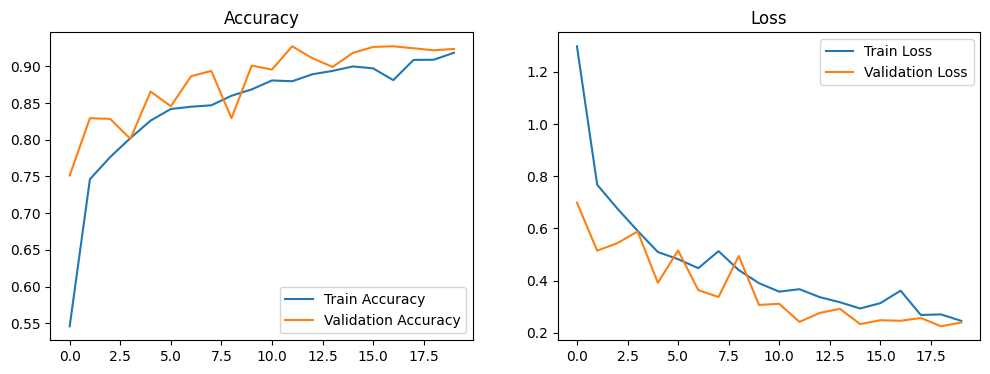

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt

# 3. CNN 모델 생성
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(train_generator.num_classes, activation='softmax')  # 클래스 개수 자동 맞춤
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. 모델 학습
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator
)

# 5. 학습 결과 시각화
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()


In [ ]:
import os

train_dir = '/content/Strawberry_DataSet/train'
test_dir = '/content/Strawberry_DataSet/test'

train_classes = set(os.listdir(train_dir))
test_classes = set(os.listdir(test_dir))

print("Train 클래스 개수:", len(train_classes))
print("Test 클래스 개수:", len(test_classes))

print("Train 클래스 목록:", sorted(train_classes))
print("Test 클래스 목록:", sorted(test_classes))

missing_classes = train_classes - test_classes
print("test에 없는 클래스:", sorted(missing_classes))

for cls in missing_classes:
    path = os.path.join(test_dir, cls)
    os.makedirs(path, exist_ok=True)  # 폴더가 없으면 생성
    print(f"빈 폴더 생성: {path}")


Train 클래스 개수: 9
Test 클래스 개수: 6
Train 클래스 목록: ['Strawberry___Leaf_scorch', 'Strawberry___healthy', 'angular', 'anthracnose_fruit_rot', 'blossom_blight', 'gray_mold', 'leaf_spot', 'powdery_mildew', 'verticillium_wilt']
Test 클래스 목록: ['angular', 'anthracnose_fruit_rot', 'blossom_blight', 'gray_mold', 'leaf_spot', 'powdery_mildew']
test에 없는 클래스: ['Strawberry___Leaf_scorch', 'Strawberry___healthy', 'verticillium_wilt']
빈 폴더 생성: /content/Strawberry_DataSet/test/Strawberry___healthy
빈 폴더 생성: /content/Strawberry_DataSet/test/verticillium_wilt
빈 폴더 생성: /content/Strawberry_DataSet/test/Strawberry___Leaf_scorch


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. 테스트용 데이터 전처리 (정규화)
test_datagen = ImageDataGenerator(rescale=1./255)

# 2. 테스트 데이터셋 생성
test_generator = test_datagen.flow_from_directory(
    '/content/Strawberry_DataSet/test',  # 실제 테스트 데이터 경로로 바꿔야 함
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',  # 반드시 categorical
    shuffle=False              # 테스트는 셔플 끔
)

# 3. 모델 평가 (이미 학습된 model 사용)
test_loss, test_acc = model.evaluate(test_generator)
print(f"테스트 정확도: {test_acc:.4f}, 테스트 손실: {test_loss:.4f}")

# 4. 학습 데이터셋 클래스 목록 (train_generator가 이미 있다고 가정)
train_classes = set(train_generator.class_indices.keys())
test_classes = set(test_generator.class_indices.keys())

print("\n테스트 데이터셋으로 평가 가능한 클래스:")
for c in sorted(test_classes):
    print(f" - {c}")

print("\n테스트 데이터셋에 없어 평가할 수 없는 클래스:")
for c in sorted(train_classes - test_classes):
    print(f" - {c}")


Found 743 images belonging to 9 classes.
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 156ms/step - accuracy: 0.8593 - loss: 0.4406
테스트 정확도: 0.8950, 테스트 손실: 0.3664

테스트 데이터셋으로 평가 가능한 클래스:
 - Strawberry___Leaf_scorch
 - Strawberry___healthy
 - angular
 - anthracnose_fruit_rot
 - blossom_blight
 - gray_mold
 - leaf_spot
 - powdery_mildew
 - verticillium_wilt

테스트 데이터셋에 없어 평가할 수 없는 클래스:


In [ ]:
model.save('strawberry_model.keras')    #저장한거임

In [ ]:
from tensorflow.keras.models import load_model

# 저장한 모델 불러오기
model_loaded = load_model('strawberry_model.keras')

# 모델 요약 출력해보기
model_loaded.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,340,244 (85.22 MB)

 Trainable params: 11,170,121 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 11,170,123 (42.61 MB)

In [ ]:
import os

file_path = 'strawberry_model.keras'
print(f"파일 존재 여부: {os.path.exists(file_path)}")
print(f"파일 크기 (bytes): {os.path.getsize(file_path)}")


파일 존재 여부: True
파일 크기 (bytes): 134088464


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

# 이미지 경로
img_path = '/content/Strawberry_DataSet/test/powdery_mildew/powdery_mildew_fruit146.jpg'  # 여기에 이미지 파일 경로 넣기

# 이미지 불러오기 및 전처리
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = img_array / 255.0  # 정규화
img_array = np.expand_dims(img_array, axis=0)  # 배치 차원 추가

# 예측
pred = model_loaded.predict(img_array)
pred_class_idx = np.argmax(pred, axis=1)[0]
index_to_class = {v: k for k, v in train_generator.class_indices.items()}
print("예측 클래스:", index_to_class[pred_class_idx])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
예측 클래스: powdery_mildew


In [ ]:
import tensorflow as tf

# 저장된 Keras 모델 불러오기
model = tf.keras.models.load_model('strawberry_model.h5')

# TFLite 변환기 생성
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# 최적화 옵션 설정 (옵션)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# TFLite 모델 변환
tflite_model = converter.convert()

# 파일로 저장
with open('strawberry_model.tflite', 'wb') as f:
    f.write(tflite_model)


Saved artifact at '/tmp/tmp_z_degpz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  133363030778960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133363030777232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133363030776464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133363030771664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133363030781264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133363030776656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133363030771856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133363030778576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133363030781840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133363030783568: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [ ]:
import os

# 현재 디렉토리의 파일 목록 보기
os.listdir()


['.config',
 'strawberry_dataset',
 'cleaned_strawberry_dataset2',
 'drive',
 'strawberry_model.keras',
 'strawberry_model.h5',
 'strawberry_model.tflite',
 'Strawberry_DataSet',
 'cleaned_strawberry_dataset',
 'strawberry_dataset2',
 'sample_data']

In [ ]:
from google.colab import files
files.download('strawberry_model.tflite')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil

# 저장 경로 지정
destination = '/content/drive/MyDrive/Strawberry_DataSet'

# 복사 실행 (기존 폴더가 있어도 덮어쓰기 허용)
shutil.copytree('/content/Strawberry_DataSet', destination, dirs_exist_ok=True)

print("Google Drive에 저장 완료!")


Google Drive에 저장 완료!


In [ ]:
import os
import random
import shutil
from pathlib import Path

base_dir = '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/딸기/데이터셋/Strawberry_DataSet/train/'
output_dir = '/content/sample_images'  # 추출 이미지 저장 폴더
os.makedirs(output_dir, exist_ok=True)

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir, class_name)

    if os.path.isdir(class_path):
        images = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        sampled_images = random.sample(images, min(3, len(images)))

        class_output_path = os.path.join(output_dir, class_name)
        os.makedirs(class_output_path, exist_ok=True)

        for img_name in sampled_images:
            src = os.path.join(class_path, img_name)
            dst = os.path.join(class_output_path, img_name)
            shutil.copy2(src, dst)

In [ ]:
import glob

for path in glob.glob(output_dir + '/*'):
    print(f"{os.path.basename(path)}: {len(os.listdir(path))} images")

leaf_spot: 3 images
blossom_blight: 3 images
verticillium_wilt: 3 images
anthracnose_fruit_rot: 3 images
angular: 3 images
Strawberry___Leaf_scorch: 3 images
Strawberry___healthy: 3 images
gray_mold: 3 images
powdery_mildew: 3 images


In [ ]:
import shutil
from google.colab import files

shutil.make_archive('/content/sample_images', 'zip', '/content/sample_images')
files.download('/content/sample_images.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import tensorflow as tf

converter = tf.lite.TFLiteConverter.from_saved_model("/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/딸기/딥러닝 모델/strawberry_model")
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS  # 기본 연산만 사용
]
tflite_model = converter.convert()

with open("model.tflite", "wb") as f:
    f.write(tflite_model)

Found 4607 images belonging to 9 classes.
Found 1102 images belonging to 9 classes.


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 3673s 25s/step - accuracy: 0.4274 - loss: 1.7057 - val_accuracy: 0.7468 - val_loss: 0.8012
Epoch 2/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 82s 567ms/step - accuracy: 0.7013 - loss: 0.9374 - val_accuracy: 0.8094 - val_loss: 0.5917
Epoch 3/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 82s 573ms/step - accuracy: 0.7718 - loss: 0.7178 - val_accuracy: 0.8512 - val_loss: 0.4828
Epoch 4/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 82s 573ms/step - accuracy: 0.8014 - loss: 0.6075 - val_accuracy: 0.8339 - val_loss: 0.5655
Epoch 5/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 82s 570ms/step - accuracy: 0.8192 - loss: 0.5495 - val_accuracy: 0.8076 - val_loss: 0.5759
Epoch 6/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 87s 606ms/step - accuracy: 0.8222 - loss: 0.5291 - val_accuracy: 0.8693 - val_loss: 0.3801
Epoch 7/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 83s 576ms/step - accuracy: 0.8423 - loss: 0.4797 - val_accuracy: 0.8775 - val_loss: 0.3831
Epoch 8/20
144/144 ━━━━━━━━━━━━━━━━━━━━ 84s 580ms/step - accuracy: 0.8443 - loss: 0

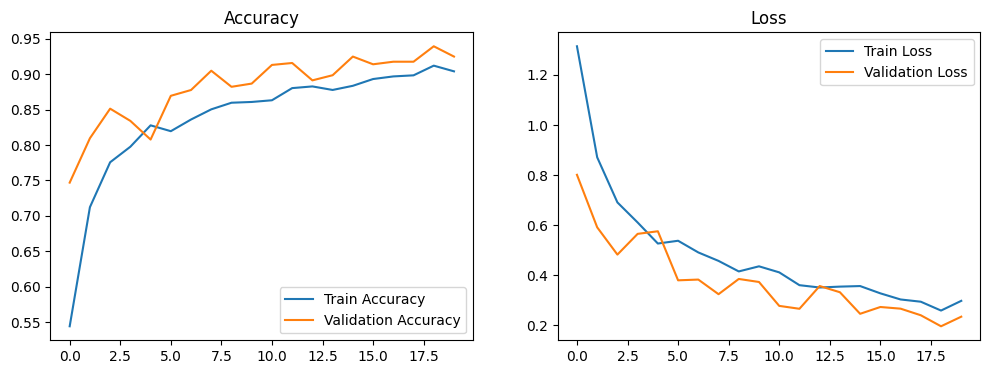

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt

# 1. 데이터 증강 및 전처리 설정
train_datagen = ImageDataGenerator(
    rescale=1./255,           # 픽셀값 0~1 사이로 정규화
    rotation_range=20,        # 이미지 랜덤 회전 범위
    width_shift_range=0.1,    # 수평 이동 범위
    height_shift_range=0.1,   # 수직 이동 범위
    horizontal_flip=True      # 좌우 뒤집기
)

val_datagen = ImageDataGenerator(rescale=1./255)  # 검증 데이터는 증강 없이 정규화만

# 2. 데이터 불러오기
train_generator = train_datagen.flow_from_directory(
    '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/딸기/데이터셋/Strawberry_DataSet/train',
    target_size=(224, 224),   # 이미지 크기 맞추기
    batch_size=32,
    class_mode='categorical'  # 다중 클래스 분류용 라벨
)

val_generator = val_datagen.flow_from_directory(
    '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/딸기/데이터셋/Strawberry_DataSet/val',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

# 3. CNN 모델 생성
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(train_generator.num_classes, activation='softmax')  # 클래스 개수 자동 맞춤
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. 모델 학습
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator
)

# 5. 학습 결과 시각화
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()


In [ ]:
import tensorflow as tf
import os

# 3. .h5 모델 경로 설정 (사용자 맞춤 경로로 바꾸세요)
h5_model_path = '/content/strawberry_model.keras'

# 4. 모델 불러오기
model = tf.keras.models.load_model(h5_model_path)

# 5. SavedModel 형식으로 저장 (tflite 변환을 위해)
saved_model_dir = '/content/saved_model'
model.export(saved_model_dir)

# 6. TFLite 변환: 연산자 버전 낮추기 (기본 연산만 사용)
converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_dir)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]  # 고버전 연산 방지
# converter.optimizations = [tf.lite.Optimize.DEFAULT]  # (선택) 양자화 시 사용

tflite_model = converter.convert()

# 7. Google Drive에 저장할 경로 설정
output_path = '/content/drive/MyDrive/초보 농부를 위한 작물 맞춤형 재배 지원 앱/딸기/strawberry_Disease.tflite'

# 8. .tflite 파일로 저장
with open(output_path, 'wb') as f:
    f.write(tflite_model)

print("✅ 변환 완료! Google Drive에 저장되었습니다:", output_path)

Saved artifact at '/content/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  136359242864336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136359242869520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136359242865488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136359242866064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136359260807312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136359260808080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136359260806544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136359260806928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136359260805008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136359260806736: TensorSpec(shape=(), dtype=tf.resource, name=None)
✅ 변환 완료! Goog